# View example 224 x 224 crops per cell line

In this notebook, we show example 224 x 224 crops centered on the nucleus for every cell line, to see how much of each crop is the single cell in the center and how much is neighboring cells.
We use the number of other nuclei in each crop from `0.evaluate_crop_sizes.ipynb`.

For each cell line, we pick the single cells whose number of other nuclei in the 224 x 224 crop is closest to the 25th, 50th (typical crop), and 75th percentiles of the cell line.
We only pick single cells that passed QC and whose crop is not at the edge of the image, so the example single cell is a real cell in the center of the crop.

Each crop is a composite of three channels (DNA in blue, ER in green, and AGP in red) after illumination correction, and the dashed box is the bounding box of the single cell in the center.
We rescale each channel of each crop to its own 1st to 99.5th percentiles, so the crops show the shapes of the cells and not the differences in intensity.

## Import libraries

In [1]:
import os
import pathlib
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from matplotlib.patches import Rectangle

from bandicoot_utils import bandicoot_check
from path_utils import get_root_dir

# root of the repository (found from the .git folder), so every path is built from the root
# and the notebook gives the same paths whether we run it from this folder or from the root
root_dir = get_root_dir()
module_dir = root_dir / "5.morphem_featurization"

## Define functions

In [2]:
def load_composite_crop(
    example: pd.Series,
    crop_size: int,
    composite_channels: dict[str, tuple[float, float, float]],
    illum_dir: pathlib.Path,
) -> tuple[np.ndarray, tuple[float, float, float, float]]:
    # top left corner of the 224 x 224 crop centered on the nucleus (the examples are not at the edge of the image)
    x_min = int(round(example["Metadata_Nuclei_Location_Center_X"] - crop_size / 2))
    y_min = int(round(example["Metadata_Nuclei_Location_Center_Y"] - crop_size / 2))

    composite = np.zeros((crop_size, crop_size, 3), dtype=np.float32)
    for channel, color in composite_channels.items():
        image = tifffile.imread(
            pathlib.Path(example[f"Image_PathName_Orig{channel}"]) / example[f"Image_FileName_Orig{channel}"]
        ).astype(np.float32)
        illum_function = np.load(illum_dir / example["Image_Metadata_Plate"] / f"{example['Image_Metadata_Plate']}_Illum{channel}.npy")
        crop = (image / illum_function)[y_min : y_min + crop_size, x_min : x_min + crop_size]

        # rescale the channel of the crop to its own 1st to 99.5th percentiles
        lower, upper = np.percentile(crop, [1, 99.5])
        crop = np.clip((crop - lower) / max(upper - lower, 1e-6), 0, 1)
        composite += crop[..., None] * np.array(color, dtype=np.float32)

    # bounding box of the single cell (union of the nucleus and cell bounding boxes) in the coordinates of the crop
    box_x_min = min(example["Nuclei_AreaShape_BoundingBoxMinimum_X"], example["Cells_AreaShape_BoundingBoxMinimum_X"]) - x_min
    box_x_max = max(example["Nuclei_AreaShape_BoundingBoxMaximum_X"], example["Cells_AreaShape_BoundingBoxMaximum_X"]) - x_min
    box_y_min = min(example["Nuclei_AreaShape_BoundingBoxMinimum_Y"], example["Cells_AreaShape_BoundingBoxMinimum_Y"]) - y_min
    box_y_max = max(example["Nuclei_AreaShape_BoundingBoxMaximum_Y"], example["Cells_AreaShape_BoundingBoxMaximum_Y"]) - y_min
    return np.clip(composite, 0, 1), (box_x_min, box_x_max, box_y_min, box_y_max)


def format_count(count: int) -> str:
    return f"{count} other nucleus" if count == 1 else f"{count} other nuclei"


def show_crop(
    ax: plt.Axes,
    crop: tuple[np.ndarray, tuple[float, float, float, float]],
    crop_size: int,
    title: str,
    fontsize: int,
) -> None:
    composite, (box_x_min, box_x_max, box_y_min, box_y_max) = crop
    ax.imshow(composite, interpolation="nearest")
    # bounding box of the single cell in the center
    ax.add_patch(
        Rectangle(
            (box_x_min - 0.5, box_y_min - 0.5),
            box_x_max - box_x_min,
            box_y_max - box_y_min,
            fill=False,
            edgecolor="white",
            linestyle="--",
            linewidth=1,
        )
    )
    ax.set_xlim(-0.5, crop_size - 0.5)
    ax.set_ylim(crop_size - 0.5, -0.5)
    ax.set_title(title, fontsize=fontsize, pad=3)
    ax.set_xticks([])
    ax.set_yticks([])

## Set paths and variables

In [3]:
# per single cell counts of the other nuclei in each crop (from 0.evaluate_crop_sizes.ipynb)
counts_path = (module_dir / "crop_evaluation/crop_neighbor_counts_per_single_cell.parquet").resolve(strict=True)

# Directory with the converted CellProfiler profiles (one folder per cell line, one parquet file per plate)
converted_dir = (root_dir / "4.preprocess_features/data/converted_profiles").resolve(strict=True)

# Directory with the QC annotations of the CellProfiler profiles (one file per cell line)
qc_results_dir = (root_dir / "4.preprocess_features/qc_results").resolve(strict=True)

# Directory with the illumination correction functions (one folder per plate)
illum_dir = (root_dir / "2.illumination_correction/illum_directory").resolve(strict=True)

image_base_dir = bandicoot_check(
    pathlib.Path(os.path.expanduser("~/mnt/bandicoot")).resolve(), root_dir
)

# Directory with the images (one folder per plate), used when the paths in the profiles are from the HPC cluster
images_dir = pathlib.Path(f"{image_base_dir}/PCCMA_data/Atlas_v2_screen")

# output figures
figure_dir = module_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
typical_figure_path = figure_dir / "example_224_crops_typical_per_cell_line.png"
all_figure_path = figure_dir / "example_224_crops_per_cell_line.png"

# size of the crop (MORPHEM_INPUT_SIZE in utils/morphem_utils.py)
crop_size = 224

# channels in the composite and their colors (RGB)
composite_channels = {"AGP": (1.0, 0.0, 0.0), "ER": (0.0, 1.0, 0.0), "DNA": (0.0, 0.4, 1.0)}

# percentiles of the cell line's number of other nuclei to show (the 50th is the typical crop)
example_percentiles = [25, 50, 75]

# columns that identify each single cell (the same as QC_MERGE_KEYS in utils/preprocess_utils.py)
qc_merge_keys = [
    "Image_Metadata_Plate",
    "Image_Metadata_Well",
    "Image_Metadata_Site",
    "Metadata_Cells_Number_Object_Number",
]

# set the seed, so we pick the same single cells when more than one is closest to a percentile
seed = 0
rng = np.random.default_rng(seed)

## Pick the example single cells

We calculate the percentiles from every single cell of the cell line (before QC, the same as the plots in `0.evaluate_crop_sizes.ipynb`), then pick the example single cells from the single cells that passed QC and are not at the edge of the image.

In [4]:
counts_df = pd.read_parquet(counts_path)

# QC annotations of every cell line (one label per single cell)
annotations_df = pd.concat(
    [pd.read_parquet(path) for path in sorted(qc_results_dir.glob("*_qc_annotations.parquet"))],
    ignore_index=True,
)
outlier_columns = [col for col in annotations_df.columns if col.endswith("_is_outlier")]
annotations_df["passed_qc"] = ~annotations_df[outlier_columns].astype(bool).any(axis=1)
counts_df = counts_df.merge(
    annotations_df[qc_merge_keys + ["passed_qc"]], on=qc_merge_keys, how="left", validate="one_to_one"
)

example_rows = []
for cell_line, cell_line_df in counts_df.groupby("Metadata_cell_line"):
    candidates_df = cell_line_df[cell_line_df["passed_qc"] & ~cell_line_df["224_crop_at_edge"]]
    for percentile in example_percentiles:
        target = cell_line_df["other_cells_in_224_crop"].quantile(percentile / 100)
        distance = (candidates_df["other_cells_in_224_crop"] - target).abs()
        closest_df = candidates_df[distance == distance.min()]
        example = closest_df.iloc[rng.integers(len(closest_df))].copy()
        example["percentile"] = percentile
        example_rows.append(example)
examples_df = pd.DataFrame(example_rows).reset_index(drop=True)

# sort the cell lines by the typical number of other nuclei (the same order as the plots in 0.evaluate_crop_sizes.ipynb)
cell_line_order = (
    counts_df.groupby("Metadata_cell_line")["other_cells_in_224_crop"].median().sort_values(kind="stable").index.tolist()
)
print(f"Picked {len(examples_df)} example single cells from {examples_df['Metadata_cell_line'].nunique()} cell lines")

Picked 162 example single cells from 54 cell lines


## Load the crops

We load the center of the nucleus, the bounding boxes, and the image paths of each example single cell from the converted profiles, then crop 224 x 224 pixels centered on the nucleus from each channel after illumination correction.

In [5]:
image_columns = [f"Image_{kind}_Orig{channel}" for channel in composite_channels for kind in ("PathName", "FileName")]
location_columns = [
    "Metadata_Nuclei_Location_Center_X",
    "Metadata_Nuclei_Location_Center_Y",
] + [
    f"{compartment}_AreaShape_BoundingBox{bound}_{axis}"
    for compartment in ("Nuclei", "Cells")
    for bound in ("Minimum", "Maximum")
    for axis in ("X", "Y")
]

# load the location and image paths of the example single cells (one converted profile per cell line and plate)
profile_dfs = []
for (cell_line, plate), job_df in examples_df.groupby(["Metadata_cell_line", "Image_Metadata_Plate"]):
    profile_df = pd.read_parquet(
        converted_dir / cell_line / f"{plate}_{cell_line}_converted.parquet",
        columns=qc_merge_keys + location_columns + image_columns,
    )
    profile_dfs.append(job_df.merge(profile_df, on=qc_merge_keys, how="left", validate="one_to_one"))
examples_df = pd.concat(profile_dfs, ignore_index=True)

# use the local path to the images when the profiles have the paths from the HPC cluster
for channel in composite_channels:
    path_column = f"Image_PathName_Orig{channel}"
    examples_df[path_column] = examples_df[path_column].apply(
        lambda path: path
        if pathlib.Path(path).exists()
        else re.sub(r"^.*PCCMA_atlas_data/", f"{images_dir}/", path)
    )


crops = {
    (example["Metadata_cell_line"], example["percentile"]): load_composite_crop(
        example, crop_size, composite_channels, illum_dir
    )
    for _, example in examples_df.iterrows()
}
counts = {
    (example["Metadata_cell_line"], example["percentile"]): example["other_cells_in_224_crop"]
    for _, example in examples_df.iterrows()
}
print(f"Loaded {len(crops)} crops")

Loaded 162 crops


## Show the typical crop of each cell line

One crop per cell line (the 50th percentile of the number of other nuclei), sorted from the fewest to the most other nuclei, so it fits on one slide.

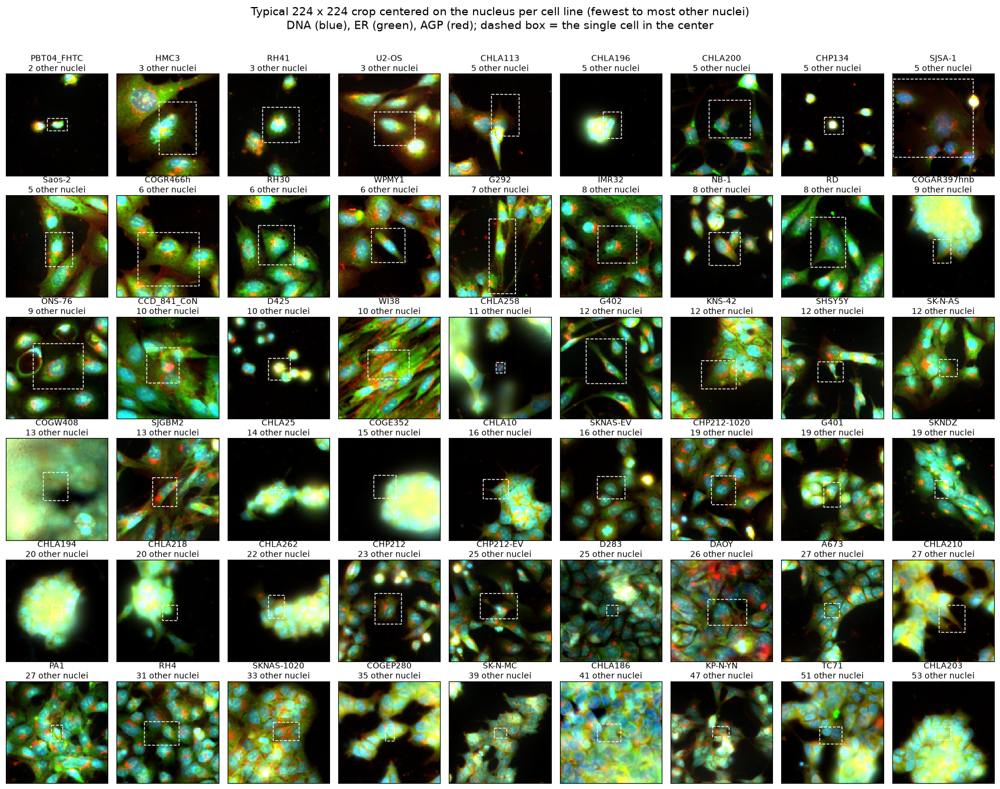

In [6]:
n_columns = 9
n_rows = int(np.ceil(len(cell_line_order) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(1.9 * n_columns, 2.15 * n_rows + 0.8))
for ax in axes.flat:
    ax.axis("off")

for ax, cell_line in zip(axes.flat, cell_line_order):
    ax.axis("on")
    show_crop(ax, crops[(cell_line, 50)], crop_size, f"{cell_line}\n{format_count(counts[(cell_line, 50)])}", fontsize=10)

fig.suptitle(
    f"Typical {crop_size} x {crop_size} crop centered on the nucleus per cell line (fewest to most other nuclei)\n"
    "DNA (blue), ER (green), AGP (red); dashed box = the single cell in the center",
    fontsize=14,
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(typical_figure_path, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Show three crops of each cell line

Three crops per cell line (the 25th, 50th, and 75th percentiles of the number of other nuclei), sorted from the fewest to the most other nuclei.
The cell lines are in three groups side by side (read down the first group, then the second and third), with a gap between the groups so each row of three crops is one cell line.

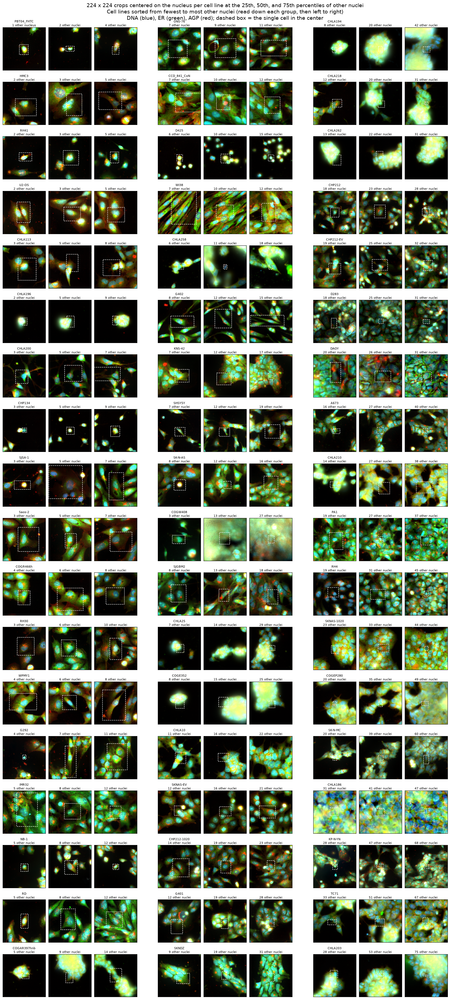

In [7]:
# three groups of cell lines side by side, each with one row per cell line and one column per percentile
n_groups = 3
rows_per_group = int(np.ceil(len(cell_line_order) / n_groups))
n_percentiles = len(example_percentiles)
# an empty, narrower column between the groups, so the three crops of each cell line stay together
gap_ratio = 0.35
n_columns = n_groups * (n_percentiles + 1) - 1
width_ratios = [gap_ratio if (column + 1) % (n_percentiles + 1) == 0 else 1 for column in range(n_columns)]
# set the spacing in inches, so the two-line titles do not run into the row above
tile_size, title_height, header_height = 1.6, 0.4, 1.0
fig_width = tile_size * sum(width_ratios) * 1.08
fig_height = (tile_size + title_height) * rows_per_group + header_height
fig, axes = plt.subplots(
    rows_per_group, n_columns, figsize=(fig_width, fig_height), gridspec_kw={"width_ratios": width_ratios}
)
fig.subplots_adjust(
    left=0.01, right=0.99, bottom=0.005, top=1 - header_height / fig_height, wspace=0.08, hspace=title_height / tile_size
)
for ax in axes.flat:
    ax.axis("off")

for index, cell_line in enumerate(cell_line_order):
    group, row = divmod(index, rows_per_group)
    for column, percentile in enumerate(example_percentiles):
        ax = axes[row, group * (n_percentiles + 1) + column]
        ax.axis("on")
        title = f"{cell_line}\n{format_count(counts[(cell_line, percentile)])}" if column == 0 else f"\n{format_count(counts[(cell_line, percentile)])}"
        show_crop(ax, crops[(cell_line, percentile)], crop_size, title, fontsize=8)

fig.suptitle(
    f"{crop_size} x {crop_size} crops centered on the nucleus per cell line at the 25th, 50th, and 75th percentiles of other nuclei\n"
    "Cell lines sorted from fewest to most other nuclei (read down each group, then left to right)\n"
    "DNA (blue), ER (green), AGP (red); dashed box = the single cell in the center",
    fontsize=14,
    y=1 - 0.1 / fig_height,
    va="top",
)
fig.savefig(all_figure_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()